In [1]:
library(tidyverse)
library(corrplot)

df <- read_tsv("../results/diversity_matrix/diversity_matrix_A.tsv", show_col_types = FALSE)
outdir <- "/Users/catg/Desktop/SOFIAC/Gitsofia/tesisbioinf-sofia/results/correlation"

etiquetas <- c(richness = "Riqueza (S)", chao1 = "Chao1", ace = "ACE",
               shannon = "Shannon", simpson = "Simpson",
               d1 = "D1", d2 = "D2", d3 = "D3", d4 = "D4",
               pielou = "Pielou", basharin = "Basharin", gini = "Gini", d50 = "D50")
metricas <- names(etiquetas)
nombres <- c(A = "Control", B = "Na\u00EFve", C = "Sangre perif\u00E9rica",
             D = "Folicular", E = "Extrafolicular + memoria")
paleta <- colorRampPalette(c("#2166AC", "#67A9CF", "#D1E5F0", "white",
                             "#FFF0B3", "#FDAE61", "#D73027"))(200)

# Todos los gráficos en un solo PDF (una página por correlograma)
pdf(file.path(outdir, "correlogramas_spearman.pdf"), width = 9.5, height = 8.5, onefile = TRUE)
tabla <- list()

correlograma <- function(datos, titulo, grupo) {
  m <- as.matrix(datos[, metricas]); colnames(m) <- etiquetas[metricas]
  rho <- suppressWarnings(cor(m, method = "spearman", use = "pairwise.complete.obs"))
  p   <- suppressWarnings(cor.mtest(m, method = "spearman", exact = FALSE)$p)
  arriba <- upper.tri(p)
  p_adj <- p
  p_adj[arriba] <- p.adjust(p[arriba], method = "BH")            # 78 pares, ajuste BH
  p_adj[lower.tri(p_adj)] <- t(p_adj)[lower.tri(p_adj)]

  corrplot(rho, method = "circle", type = "upper", diag = FALSE,
           col = paleta, col.lim = c(-1, 1),
           p.mat = p_adj, sig.level = c(0.001, 0.01, 0.05),
           insig = "label_sig", pch.cex = 0.9, pch.col = "black",
           tl.col = "black", tl.srt = 45, tl.cex = 0.85, cl.cex = 0.8,
           addgrid.col = "grey85", na.label = " ",
           title = titulo, mar = c(3, 1, 3, 1))
  mtext("Color y tama\u00F1o: coeficiente de Spearman (rho).   * p < 0,05;  ** p < 0,01;  *** p < 0,001 (ajuste BH)",
        side = 1, line = 1.5, cex = 0.7)

  # Guardar los pares en formato largo
  i <- which(arriba, arr.ind = TRUE)
  tibble(grupo = grupo, metrica_1 = rownames(rho)[i[, 1]], metrica_2 = colnames(rho)[i[, 2]],
         rho = round(rho[i], 3), p_BH = signif(p_adj[i], 3))
}

# (1) General: los 55 repertorios
tabla[["General"]] <- correlograma(df, "Todos los escenarios y profundidades (n = 55)", "General")

# (2) Por escenario: sus 11 profundidades
for (esc in names(nombres)) {
  datos_esc <- df %>% filter(condition == esc) %>% arrange(size)
  tabla[[esc]] <- correlograma(datos_esc,
                    paste0("Escenario ", esc, " - ", nombres[esc], " (n = ", nrow(datos_esc), " profundidades)"),
                    paste0("Escenario ", esc))
}
dev.off()

# Una sola tabla con todos los rho y p ajustados
write_tsv(bind_rows(tabla), file.path(outdir, "correlaciones_spearman.tsv"))

-- Attaching core tidyverse packages ------------------------ tidyverse 2.0.0 --
v dplyr     1.2.1     v readr     2.1.5
v forcats   1.0.1     v stringr   1.6.0
v ggplot2   4.0.0     v tibble    3.3.0
v lubridate 1.9.5     v tidyr     1.3.1
v purrr     1.2.0     
-- Conflicts ------------------------------------------ tidyverse_conflicts() --
x dplyr::filter() masks stats::filter()
x dplyr::lag()    masks stats::lag()
i Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
corrplot 0.95 loaded



agg_record_a3a56bd7636 
                     2

# A tibble: 13 x 6
   metrica         A     B     C     D     E
   <chr>       <dbl> <dbl> <dbl> <dbl> <dbl>
 1 ACE            NA    NA    NA    NA    NA
 2 Basharin    51200 51200 51200 51200 51200
 3 Chao1          NA    NA    NA    NA    NA
 4 D1             NA    NA    NA    NA    NA
 5 D2          12800 25600 12800 12800   800
 6 D3          12800  6400  6400  1600  1600
 7 D4          12800  1600  6400  1600  6400
 8 D50         12800    NA    NA 51200  3200
 9 Gini        51200    NA    NA    NA 25600
10 Pielou      51200 25600 25600 51200 51200
11 Riqueza (S)    NA    NA    NA    NA    NA
12 Shannon     51200 51200 51200 51200 51200
13 Simpson     12800 25600 12800 12800   800


Warning message:
"There were 2 warnings in `mutate()`.
The first warning was:
i In argument: `prof = factor(...)`.
Caused by warning in `prettyNum()`:
! 'big.mark' and 'decimal.mark' are both '.', which could be confusing
i Run `dplyr::last_dplyr_warnings()` to see the 1 remaining warning."


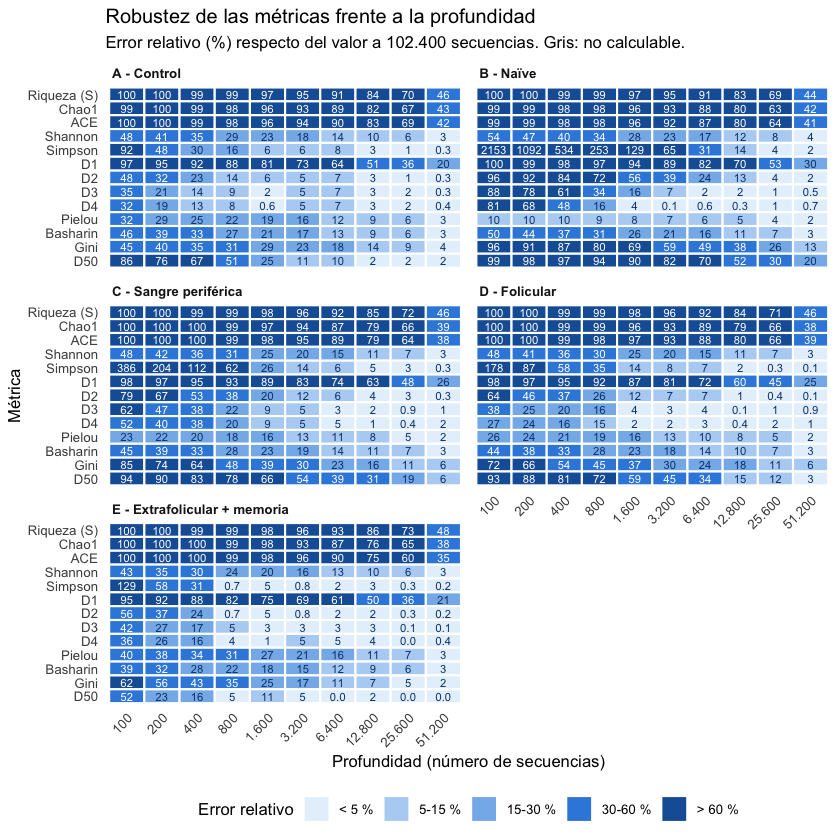

In [2]:
library(tidyverse)

# Matriz de diversidad del downsampling (cambia la ruta para usar otra matriz)
df <- read_tsv("../results/diversity_matrix/diversity_matrix_DOWN.tsv", show_col_types = FALSE)
outdir <- "/Users/catg/Desktop/SOFIAC/Gitsofia/tesisbioinf-sofia/results/correlation"
UMBRAL <- 5   # % de error bajo el cual la métrica se considera estable

etiquetas <- c(richness = "Riqueza (S)", chao1 = "Chao1", ace = "ACE",
               shannon = "Shannon", simpson = "Simpson",
               d1 = "D1", d2 = "D2", d3 = "D3", d4 = "D4",
               pielou = "Pielou", basharin = "Basharin", gini = "Gini", d50 = "D50")
nombres <- c(A = "Control", B = "Na\u00EFve", C = "Sangre perif\u00E9rica",
             D = "Folicular", E = "Extrafolicular + memoria")
maxima <- max(df$size)

# 1. Pasar a formato largo: una fila por escenario, profundidad y métrica
largo <- df %>%
  select(condition, size, all_of(names(etiquetas))) %>%
  pivot_longer(all_of(names(etiquetas)), names_to = "metrica", values_to = "valor")

# 2. Valor de referencia: el de la profundidad máxima (102.400)
ref <- largo %>% filter(size == maxima) %>% select(condition, metrica, ref = valor)

# 3. Error relativo (%) = |valor - referencia| / referencia x 100
tabla_error <- largo %>%
  filter(size < maxima) %>%
  left_join(ref, by = c("condition", "metrica")) %>%
  mutate(error = if_else(ref == 0, NA_real_, abs(valor - ref) / abs(ref) * 100))

# 4. Profundidad desde la que la métrica queda bajo el umbral (y ya no vuelve a subir)
estable <- tabla_error %>%
  group_by(condition, metrica) %>%
  arrange(size, .by_group = TRUE) %>%
  summarise(estable_desde = {
    ok <- rev(cumall(rev(coalesce(error < UMBRAL, FALSE))))
    if (any(ok)) min(size[ok]) else NA_real_
  }, .groups = "drop") %>%
  mutate(metrica = etiquetas[metrica]) %>%
  pivot_wider(names_from = condition, values_from = estable_desde)
print(estable)   # NA = no se estabiliza antes de 102.400

# 5. Mapa de calor
profs <- sort(unique(tabla_error$size))
graf <- tabla_error %>%
  mutate(metrica = factor(etiquetas[metrica], levels = rev(etiquetas)),
         prof = factor(formatC(size, format = "d", big.mark = "."),
                       levels = formatC(profs, format = "d", big.mark = ".")),
         escenario = paste0(condition, " - ", nombres[condition]),
         rango = cut(error, c(-Inf, 5, 15, 30, 60, Inf), right = FALSE,
                     labels = c("< 5 %", "5-15 %", "15-30 %", "30-60 %", "> 60 %")),
         texto = ifelse(is.na(error), "", ifelse(error < 1, sprintf("%.1f", error), sprintf("%.0f", error))),
         oscuro = coalesce(error >= 30, FALSE))

p <- ggplot(graf, aes(prof, metrica, fill = rango)) +
  geom_tile(colour = "white", linewidth = 0.6) +
  geom_text(aes(label = texto, colour = oscuro), size = 2.4) +
  scale_fill_manual(values = c("< 5 %" = "#E6F1FB", "5-15 %" = "#B5D4F4", "15-30 %" = "#85B7EB",
                               "30-60 %" = "#378ADD", "> 60 %" = "#185FA5"),
                    na.value = "grey85", drop = FALSE, name = "Error relativo") +
  scale_colour_manual(values = c(`FALSE` = "#0C447C", `TRUE` = "white"), guide = "none") +
  facet_wrap(~ escenario, ncol = 2) +
  labs(title = "Robustez de las m\u00E9tricas frente a la profundidad",
       subtitle = "Error relativo (%) respecto del valor a 102.400 secuencias. Gris: no calculable.",
       x = "Profundidad (n\u00FAmero de secuencias)", y = "M\u00E9trica") +
  theme_minimal(base_size = 10) +
  theme(panel.grid = element_blank(),
        axis.text.x = element_text(angle = 45, hjust = 1),
        strip.text = element_text(face = "bold", hjust = 0),
        legend.position = "bottom")

print(p)
ggsave(file.path(outdir, "error_relativo_robustez.pdf"), p, width = 13, height = 15)

# 6. Tablas
write_tsv(tabla_error, file.path(outdir, "error_relativo_robustez.tsv"))
write_tsv(estable, file.path(outdir, "profundidad_estable.tsv"))

# A tibble: 13 x 6
   metrica         A     B     C     D     E
   <chr>       <dbl> <dbl> <dbl> <dbl> <dbl>
 1 ACE            NA    NA    NA    NA    NA
 2 Basharin    51200 51200 51200 51200 51200
 3 Chao1          NA    NA    NA    NA    NA
 4 D1             NA    NA    NA    NA    NA
 5 D2          12800 25600 12800 12800   800
 6 D3          12800  6400  6400  1600  1600
 7 D4          12800  1600  6400  1600  6400
 8 D50         12800    NA    NA 51200  3200
 9 Gini        51200    NA    NA    NA 25600
10 Pielou      51200 25600 25600 51200 51200
11 Riqueza (S)    NA    NA    NA    NA    NA
12 Shannon     51200 51200 51200 51200 51200
13 Simpson     12800 25600 12800 12800   800


Warning message:
"There were 2 warnings in `mutate()`.
The first warning was:
i In argument: `prof = factor(...)`.
Caused by warning in `prettyNum()`:
! 'big.mark' and 'decimal.mark' are both '.', which could be confusing
i Run `dplyr::last_dplyr_warnings()` to see the 1 remaining warning."


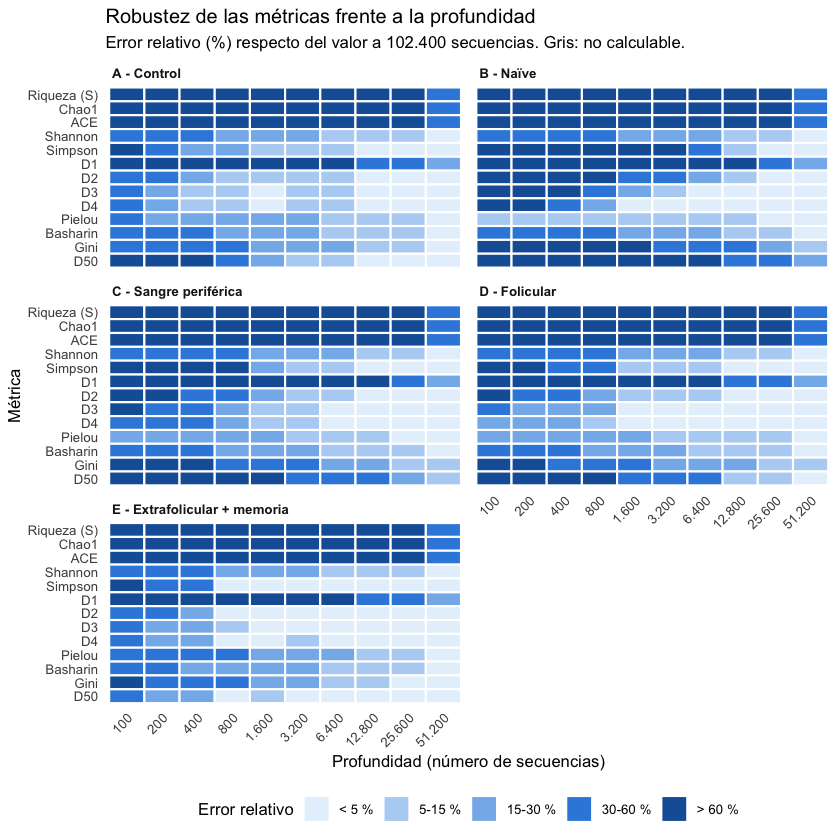

In [4]:
library(tidyverse)

# Matriz de diversidad del downsampling (cambia la ruta para usar otra matriz)
df <- read_tsv("../results/diversity_matrix/diversity_matrix_DOWN.tsv", show_col_types = FALSE)
outdir <- "/Users/catg/Desktop/SOFIAC/Gitsofia/tesisbioinf-sofia/results/correlation"
UMBRAL <- 5   # % de error bajo el cual la métrica se considera estable

etiquetas <- c(richness = "Riqueza (S)", chao1 = "Chao1", ace = "ACE",
               shannon = "Shannon", simpson = "Simpson",
               d1 = "D1", d2 = "D2", d3 = "D3", d4 = "D4",
               pielou = "Pielou", basharin = "Basharin", gini = "Gini", d50 = "D50")
nombres <- c(A = "Control", B = "Na\u00EFve", C = "Sangre perif\u00E9rica",
             D = "Folicular", E = "Extrafolicular + memoria")
maxima <- max(df$size)

# 1. Pasar a formato largo: una fila por escenario, profundidad y métrica
largo <- df %>%
  select(condition, size, all_of(names(etiquetas))) %>%
  pivot_longer(all_of(names(etiquetas)), names_to = "metrica", values_to = "valor")

# 2. Valor de referencia: el de la profundidad máxima (102.400)
ref <- largo %>% filter(size == maxima) %>% select(condition, metrica, ref = valor)

# 3. Error relativo (%) = |valor - referencia| / referencia x 100
tabla_error <- largo %>%
  filter(size < maxima) %>%
  left_join(ref, by = c("condition", "metrica")) %>%
  mutate(error = if_else(ref == 0, NA_real_, abs(valor - ref) / abs(ref) * 100))

# 4. Profundidad desde la que la métrica queda bajo el umbral (y ya no vuelve a subir)
estable <- tabla_error %>%
  group_by(condition, metrica) %>%
  arrange(size, .by_group = TRUE) %>%
  summarise(estable_desde = {
    ok <- rev(cumall(rev(coalesce(error < UMBRAL, FALSE))))
    if (any(ok)) min(size[ok]) else NA_real_
  }, .groups = "drop") %>%
  mutate(metrica = etiquetas[metrica]) %>%
  pivot_wider(names_from = condition, values_from = estable_desde)
print(estable)   # NA = no se estabiliza antes de 102.400

# 5. Mapa de calor (solo colores)
profs <- sort(unique(tabla_error$size))
graf <- tabla_error %>%
  mutate(metrica = factor(etiquetas[metrica], levels = rev(etiquetas)),
         prof = factor(formatC(size, format = "d", big.mark = "."),
                       levels = formatC(profs, format = "d", big.mark = ".")),
         escenario = paste0(condition, " - ", nombres[condition]),
         rango = cut(error, c(-Inf, 5, 15, 30, 60, Inf), right = FALSE,
                     labels = c("< 5 %", "5-15 %", "15-30 %", "30-60 %", "> 60 %")))

p <- ggplot(graf, aes(prof, metrica, fill = rango)) +
  geom_tile(colour = "white", linewidth = 0.6) +
  scale_fill_manual(values = c("< 5 %" = "#E6F1FB", "5-15 %" = "#B5D4F4", "15-30 %" = "#85B7EB",
                               "30-60 %" = "#378ADD", "> 60 %" = "#185FA5"),
                    na.value = "grey85", drop = FALSE, name = "Error relativo") +
  facet_wrap(~ escenario, ncol = 2) +
  labs(title = "Robustez de las m\u00E9tricas frente a la profundidad",
       subtitle = "Error relativo (%) respecto del valor a 102.400 secuencias. Gris: no calculable.",
       x = "Profundidad (n\u00FAmero de secuencias)", y = "M\u00E9trica") +
  theme_minimal(base_size = 10) +
  theme(panel.grid = element_blank(),
        axis.text.x = element_text(angle = 45, hjust = 1),
        strip.text = element_text(face = "bold", hjust = 0),
        legend.position = "bottom")

print(p)
ggsave(file.path(outdir, "error_relativo_robustez.pdf"), p, width = 13, height = 15)

# 6. Tablas
write_tsv(tabla_error, file.path(outdir, "error_relativo_robustez.tsv"))
write_tsv(estable, file.path(outdir, "profundidad_estable.tsv"))